In [1]:
!pip install torch torchvision
!pip install scikit-image
!pip install pytorch-fid
!pip install denoising-diffusion-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [denoising-diffusion-pytorch]


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torch.utils.data import random_split

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [3]:
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)


In [4]:
transform = transforms.ToTensor()

dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 13.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.67MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.4MB/s]


In [5]:
train_size = int(0.8 * len(dataset))
val_size = int(0.1 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset,test_dataset,val_dataset = random_split(
    dataset,
    [train_size,test_size,val_size]
)

In [6]:
batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [7]:
#Ini adalah class untuk Metode MLPClassifier
class MLPClassifier(nn.Module):

    def __init__(self):

        super().__init__()

        self.fc1 = nn.Linear(784,256)

        self.fc2 = nn.Linear(256,64)

        self.fc3 = nn.Linear(64,10)

    def forward(self,x):

        x = x.view(-1,784)

        h1 = F.relu(self.fc1(x))

        z = F.relu(self.fc2(h1))

        out = self.fc3(z)

        return out,z

In [8]:
classifier = MLPClassifier().to(device) #Kita terapkan dalam variabel baru

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    classifier.parameters(), #Menggunakan jenis optimizer Adam karena paling bagus
    lr=1e-3
)

In [9]:
epochs = 10 #Saya gunakan epoch 10 supaya tidak terlalu berat komputasinya
#Ini adalah proses trainingnya
for epoch in range(epochs):

    classifier.train()

    running_loss = 0

    for images,labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        output,z = classifier(images)

        loss = criterion(
            output,
            labels
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}",
        running_loss/len(train_loader)
    )

Epoch 1 0.6138189427057902
Epoch 2 0.4233453753789266
Epoch 3 0.37412211481730145
Epoch 4 0.34427133830388384
Epoch 5 0.32409954023361204
Epoch 6 0.30504092172781627
Epoch 7 0.29213967196146645
Epoch 8 0.27999662605921427
Epoch 9 0.2688899664282799
Epoch 10 0.2596679108540217


In [10]:
classifier.eval()
#Sekarang kita akan melakukan testing untuk melihat akurasinya

correct = 0
total = 0

with torch.no_grad():

    for images,labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        output,z = classifier(images)

        pred = output.argmax(1)

        correct += (
            pred == labels
        ).sum().item()

        total += labels.size(0)

print(
    "Hasil Accuracy:",
    correct/total
)


Hasil Accuracy: 0.8886666666666667


In [11]:
W1 = classifier.fc1.weight.data
W2 = classifier.fc2.weight.data
W3 = classifier.fc3.weight.data

In [12]:
y = torch.zeros(10).to(device)

y[3] = 1

In [13]:
z_hat = torch.relu(
    W3.T @ y
)

h_hat = torch.relu(
    W2.T @ z_hat
)

x_hat = torch.sigmoid(
    W1.T @ h_hat
)

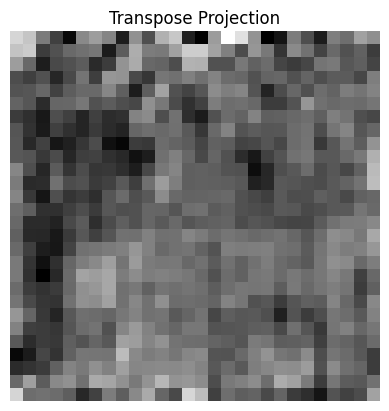

In [14]:
plt.imshow(
    x_hat.reshape(28,28).cpu(),
    cmap='gray'
)

plt.title(
    "Transpose Projection"
)

plt.axis('off')
#Kalau gambar tidak jelas, berarti dia berhasil, kalau nggak berarti ada decoder yang kemasuk. Ini bertujuan untuk bentuk awal rekonstruksi

plt.show()

In [15]:
#Seakarang kita buat kelas untuk Autoencodernya
class Autoencoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.encoder = nn.Sequential(

            nn.Linear(784,256),

            nn.ReLU(),

            nn.Linear(256,64)
        )

        self.decoder = nn.Sequential(

            nn.Linear(64,256),

            nn.ReLU(),

            nn.Linear(256,784),

            nn.Sigmoid()
        )

    def forward(self,x):

        x = x.view(-1,784)

        z = self.encoder(x)

        recon = self.decoder(z)

        return recon,z

In [16]:
ae = Autoencoder().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    ae.parameters(),
    lr=1e-3
)

In [17]:
for epoch in range(10):

    total_loss = 0

    for images,_ in train_loader:

        images = images.to(device)

        recon,z = ae(images)

        loss = criterion(
            recon,
            images.view(-1,784)
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        epoch+1,
        total_loss/len(train_loader)
    )

1 0.03411099528272947
2 0.017413861547907195
3 0.014685154927273592
4 0.013060588225722312
5 0.011977415199081102
6 0.011174325081209342
7 0.010536077705522378
8 0.010041034782926242
9 0.009615087419748307
10 0.009250494642804067


In [18]:
#Sparse AE
sparse_ae = Autoencoder().to(device)

optimizer = torch.optim.Adam(
    sparse_ae.parameters(),
    lr=1e-3
)

lambda_sparse = 1e-3

In [19]:
for epoch in range(10):

    total_loss = 0

    for images,_ in train_loader:

        images = images.to(device)

        recon,z = sparse_ae(images)

        mse = criterion(
            recon,
            images.view(-1,784)
        )

        sparse_penalty = z.abs().mean()

        loss = mse + (
            lambda_sparse *
            sparse_penalty
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        epoch+1,
        total_loss/len(train_loader)
    )

1 0.03509009689092636
2 0.017926556423306466
3 0.015140088923275471
4 0.01357701043287913
5 0.01242827067275842
6 0.01160046641031901
7 0.010872031745811304
8 0.010353366446991762
9 0.009887921440104643
10 0.009498046512405078


In [20]:
class VAE(nn.Module):

    def __init__(self):

        super().__init__()

        self.fc1 = nn.Linear(784,256)

        self.fc_mu = nn.Linear(256,64)

        self.fc_logvar = nn.Linear(256,64)

        self.fc3 = nn.Linear(64,256)

        self.fc4 = nn.Linear(256,784)

    def encode(self,x):

        h = F.relu(
            self.fc1(x)
        )

        return (
            self.fc_mu(h),
            self.fc_logvar(h)
        )

    def reparameterize(
        self,
        mu,
        logvar
    ):

        std = torch.exp(
            0.5*logvar
        )

        eps = torch.randn_like(std)

        return mu + eps*std

    def decode(self,z):

        h = F.relu(
            self.fc3(z)
        )

        return torch.sigmoid(
            self.fc4(h)
        )

    def forward(self,x):

        x = x.view(-1,784)

        mu,logvar = self.encode(x)

        z = self.reparameterize(
            mu,
            logvar
        )

        recon = self.decode(z)

        return recon,mu,logvar

In [21]:
vae = VAE().to(device)

optimizer = torch.optim.Adam(
    vae.parameters(),
    lr=1e-3
)

In [22]:
for epoch in range(10):

    total_loss = 0

    for images,_ in train_loader:

        images = images.to(device)

        recon,mu,logvar = vae(images)

        x = images.view(-1,784)

        recon_loss = F.binary_cross_entropy(
            recon,
            x,
            reduction='sum'
        )

        kl = -0.5 * torch.sum(
            1 +
            logvar -
            mu.pow(2) -
            logvar.exp()
        )

        loss = recon_loss + kl

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(epoch,total_loss)

0 14668602.734375
1 12941138.8046875
2 12500488.681640625
3 12221089.3671875
4 12060091.79296875
5 11955397.470703125
6 11883546.45703125
7 11832333.990234375
8 11791738.76171875
9 11759686.3046875


In [23]:
def evaluate_model(
    model,
    loader
):

    model.eval()

    mse_list = []
    psnr_list = []
    ssim_list = []

    with torch.no_grad():

        for images,_ in loader:

            images = images.to(device)

            recon,_ = model(images)

            recon = recon.view(
                -1,28,28
            )

            images = images.squeeze(1)

            for i in range(
                len(images)
            ):

                img = images[i].cpu().numpy()

                rec = recon[i].cpu().numpy()

                mse = np.mean(
                    (img-rec)**2
                )

                p = peak_signal_noise_ratio(
                    img,
                    rec,
                    data_range=1
                )

                s = structural_similarity(
                    img,
                    rec,
                    data_range=1
                )

                mse_list.append(mse)
                psnr_list.append(p)
                ssim_list.append(s)

    return {

        "MSE":np.mean(mse_list),

        "PSNR":np.mean(psnr_list),

        "SSIM":np.mean(ssim_list)
    }

In [24]:
print(
    "AE Evaluation: ",
    evaluate_model(
        ae,
        test_loader
    )
)

print(
    "Sparse AE Evaluation: ",
    evaluate_model(
        sparse_ae,
        test_loader
    )
)

AE Evaluation:  {'MSE': np.float32(0.009214256), 'PSNR': np.float64(21.3000473567572), 'SSIM': np.float64(0.7716984550138039)}
Sparse AE Evaluation:  {'MSE': np.float32(0.008950473), 'PSNR': np.float64(21.441081613300675), 'SSIM': np.float64(0.7723151321050857)}


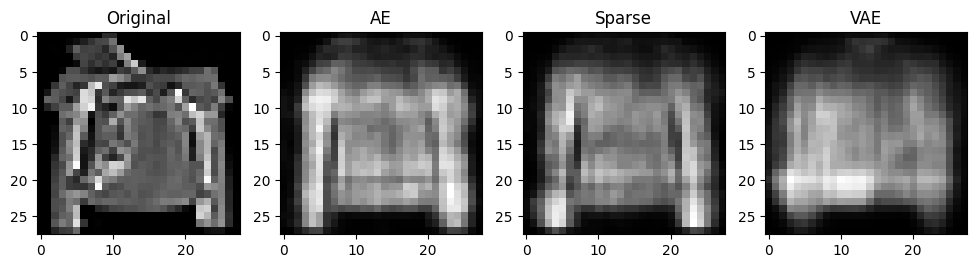

In [25]:
images,_ = next(
    iter(test_loader)
)

img = images[0].unsqueeze(0).to(device)

with torch.no_grad():

    ae_rec,_ = ae(img)

    sparse_rec,_ = sparse_ae(img)

    vae_rec,_,_ = vae(img)

plt.figure(figsize=(12,4))

plt.subplot(1,4,1)
plt.imshow(
    img.cpu().squeeze(),
    cmap='gray'
)
plt.title("Original")

plt.subplot(1,4,2)
plt.imshow(
    ae_rec.cpu().reshape(28,28),
    cmap='gray'
)
plt.title("AE")

plt.subplot(1,4,3)
plt.imshow(
    sparse_rec.cpu().reshape(28,28),
    cmap='gray'
)
plt.title("Sparse")

plt.subplot(1,4,4)
plt.imshow(
    vae_rec.cpu().reshape(28,28),
    cmap='gray'
)
plt.title("VAE")

plt.show()

In [26]:
class Generator(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(100,128),
            nn.ReLU(),

            nn.Linear(128,256),
            nn.ReLU(),

            nn.Linear(256,784),

            nn.Tanh()
        )

    def forward(self,z):
        return self.net(z)

In [27]:
class Discriminator(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(784,256),
            nn.LeakyReLU(0.2),

            nn.Linear(256,128),
            nn.LeakyReLU(0.2),

            nn.Linear(128,1),

            nn.Sigmoid()
        )

    def forward(self,x):
        return self.net(x)

In [28]:
G = Generator().to(device)
D = Discriminator().to(device)

criterion = nn.BCELoss()

g_optimizer = torch.optim.Adam(
    G.parameters(),
    lr=0.0002
)

d_optimizer = torch.optim.Adam(
    D.parameters(),
    lr=0.0002
)

In [29]:
for epoch in range(10):

    for images,_ in train_loader:

        images = images.to(device)

        real = images.view(-1,784)

        batch_size = real.size(0)

        real_labels = torch.ones(
            batch_size,
            1
        ).to(device)

        fake_labels = torch.zeros(
            batch_size,
            1
        ).to(device)

        ################################################
        # Train D
        ################################################

        z = torch.randn(
            batch_size,
            100
        ).to(device)

        fake = G(z)

        real_loss = criterion(
            D(real),
            real_labels
        )

        fake_loss = criterion(
            D(fake.detach()),
            fake_labels
        )

        d_loss = (
            real_loss +
            fake_loss
        )

        d_optimizer.zero_grad()

        d_loss.backward()

        d_optimizer.step()

        ################################################
        # Train G
        ################################################

        z = torch.randn(
            batch_size,
            100
        ).to(device)

        fake = G(z)

        g_loss = criterion(
            D(fake),
            real_labels
        )

        g_optimizer.zero_grad()

        g_loss.backward()

        g_optimizer.step()

    print(
        epoch,
        d_loss.item(),
        g_loss.item()
    )

0 0.6961789131164551 3.011688709259033
1 0.8132675886154175 1.756596565246582
2 0.7545360326766968 1.7189104557037354
3 0.8639901280403137 1.718515396118164
4 0.365682452917099 2.580847978591919
5 0.6358479261398315 4.272369384765625
6 0.7040280103683472 3.0618534088134766
7 0.5690062642097473 2.525571346282959
8 0.8404480218887329 2.874645233154297
9 0.26113420724868774 3.7792344093322754


In [30]:
class DCGenerator(nn.Module): #ini juga adalah GAN tapi dalam versi konvolusinya

    def __init__(self):

        super().__init__()

        self.model = nn.Sequential(

            nn.ConvTranspose2d(
                100,
                128,
                7,
                1,
                0
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(),

            nn.ConvTranspose2d(
                128,
                64,
                4,
                2,
                1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(),

            nn.Conv2d(
                64,
                1,
                3,
                1,
                1
            ),

            nn.Tanh()
        )

    def forward(self,z):
        return self.model(z)

In [31]:
class DCDiscriminator(nn.Module):

    def __init__(self):

        super().__init__()

        self.model = nn.Sequential(

            nn.Conv2d(
                1,
                64,
                4,
                2,
                1
            ),

            nn.LeakyReLU(0.2),

            nn.Conv2d(
                64,
                128,
                4,
                2,
                1
            ),

            nn.LeakyReLU(0.2),

            nn.Flatten(),

            nn.Linear(
                128*7*7,
                1
            ),

            nn.Sigmoid()
        )

    def forward(self,x):
        return self.model(x)

In [32]:
!pip install denoising-diffusion-pytorch

In [33]:
from denoising_diffusion_pytorch import (
    Unet,
    GaussianDiffusion
)
ddpm_model = Unet(
    dim=32,
    channels=1,
    dim_mults=(1,2)
)
diffusion = GaussianDiffusion(
    ddpm_model,
    image_size=28,
    timesteps=100
).to(device)

In [34]:
optimizer = torch.optim.Adam(
    diffusion.parameters(),
    lr=1e-4
)
#DDPM paling lama karena harus mengembalikan noise secara bertahap melalui ratusan hingga ribuan langkah yang secara berurutan untuk membuat satu gambar

ddpm_losses = []

for epoch in range(3):

    for images,_ in train_loader:

        images = images.to(device)

        loss = diffusion(images)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

    ddpm_losses.append(
        loss.item()
    )

    print(
        f"Epoch {epoch+1}",
        loss.item()
    )

Epoch 1 0.09723847359418869
Epoch 2 0.10049095749855042
Epoch 3 0.08973389118909836


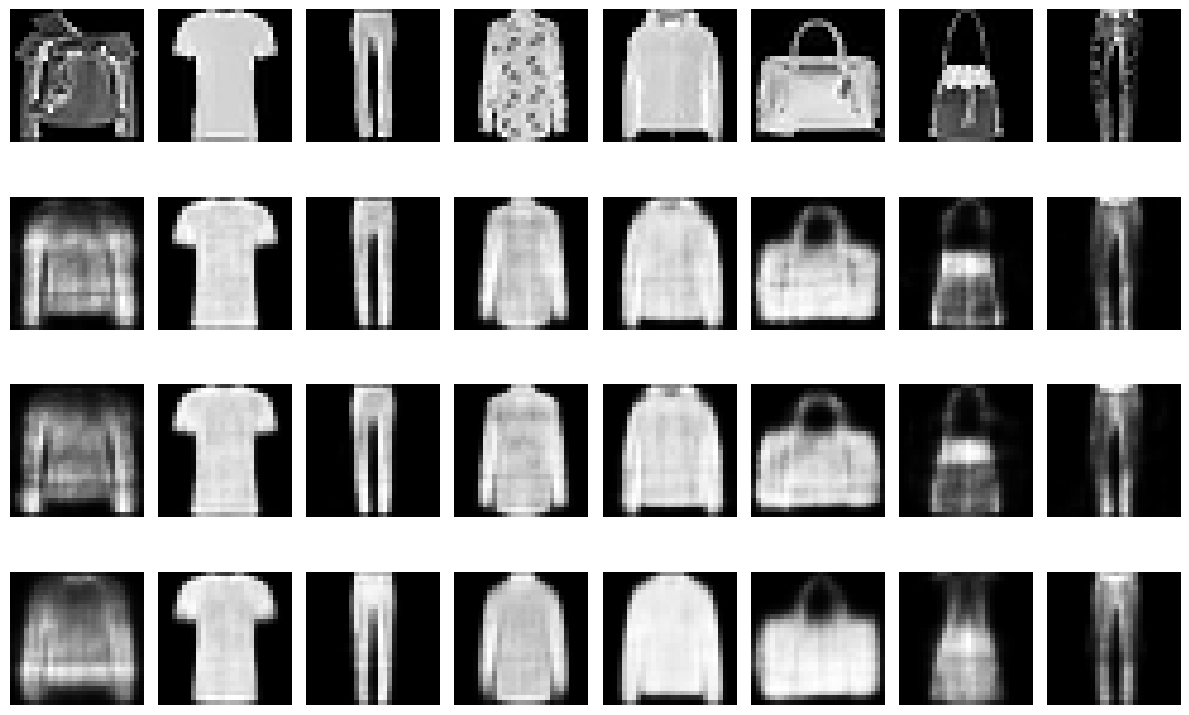

In [35]:
test_images, _ = next(iter(test_loader))

test_images = test_images[:8].to(device)

with torch.no_grad():

    ae_recon,_ = ae(test_images)

    sparse_recon,_ = sparse_ae(test_images)

    vae_recon,_,_ = vae(test_images)

plt.figure(figsize=(12,8))

for i in range(8):

    plt.subplot(4,8,i+1)
    plt.imshow(test_images[i].cpu().squeeze(), cmap='gray')
    plt.axis('off')

    plt.subplot(4,8,i+9)
    plt.imshow(ae_recon[i].cpu().reshape(28,28), cmap='gray')
    plt.axis('off')

    plt.subplot(4,8,i+17)
    plt.imshow(sparse_recon[i].cpu().reshape(28,28), cmap='gray')
    plt.axis('off')

    plt.subplot(4,8,i+25)
    plt.imshow(vae_recon[i].cpu().reshape(28,28), cmap='gray')
    plt.axis('off')

plt.tight_layout()

plt.savefig(
    "figure1_reconstruction.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [36]:
#VAE
#GAN
#DCGAN
#DDPM
with torch.no_grad():

    z = torch.randn(16,64).to(device)

    samples = vae.decode(z)

    samples = samples.cpu()
plt.savefig("figure2_gan.png")
plt.savefig("figure2_dcgan.png")

<Figure size 640x480 with 0 Axes>

In [37]:
# Panel A = VAE
# Panel B = GAN
# Panel C = DCGAN
# Panel D = DDPM
with torch.no_grad():

    z = torch.randn(
        16,
        64
    ).to(device)

    vae_samples = vae.decode(z)


In [38]:
G_dc = DCGenerator().to(device)

D_dc = DCDiscriminator().to(device)

In [39]:
with torch.no_grad():

    z = torch.randn(
        16,
        100
    ).to(device)

    gan_samples = G(z)

In [40]:
with torch.no_grad():

    z = torch.randn(
        16,
        100,
        1,
        1
    ).to(device)

    dcgan_samples = G_dc(z)


In [41]:
ddpm_samples = diffusion.sample(
    batch_size=16
).cpu()

sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

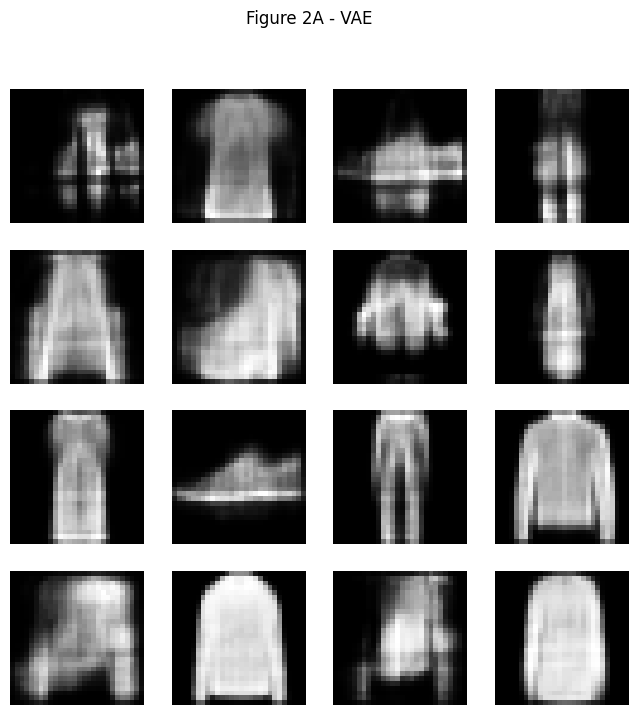

In [42]:
fig,axes = plt.subplots(
    4,
    4,
    figsize=(8,8)
)

for i in range(16):

    axes[i//4,i%4].imshow(
        vae_samples[i]
        .cpu()
        .reshape(28,28),
        cmap='gray'
    )

    axes[i//4,i%4].axis('off')

plt.suptitle("Figure 2A - VAE")

plt.savefig(
    "Figure2A_VAE.png",
    dpi=300
)

plt.show()

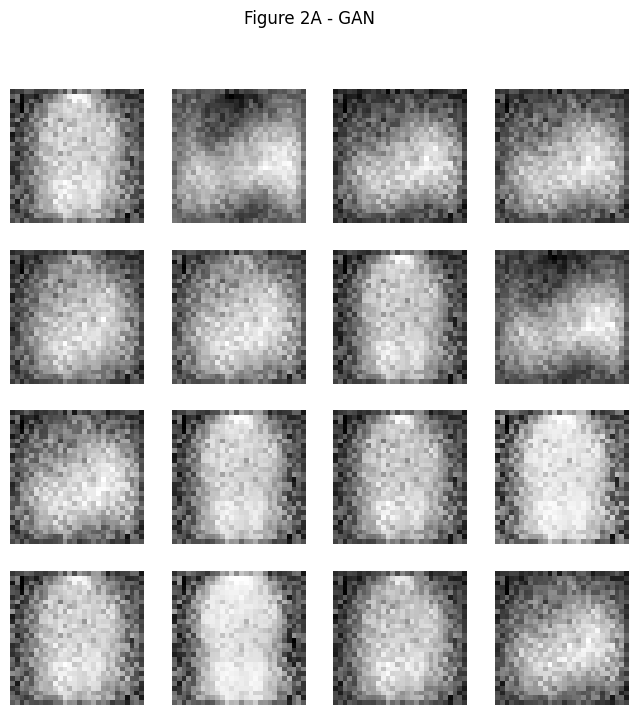

In [43]:
fig,axes = plt.subplots(
    4,
    4,
    figsize=(8,8)
)

for i in range(16):

    axes[i//4,i%4].imshow(
        gan_samples[i]
        .cpu()
        .reshape(28,28),
        cmap='gray'
    )

    axes[i//4,i%4].axis('off')

plt.suptitle("Figure 2A - GAN")

plt.savefig(
    "Figure2A_GAN.png",
    dpi=300
)

plt.show()

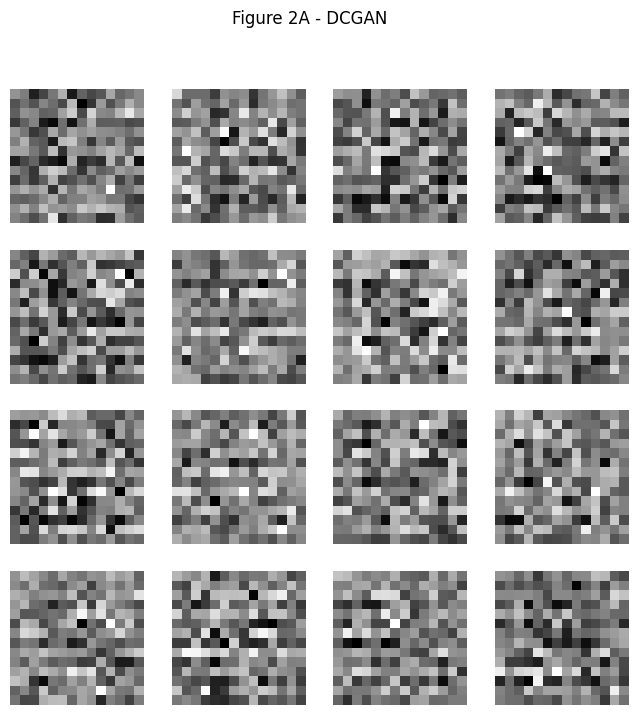

In [44]:
fig,axes = plt.subplots(
    4,
    4,
    figsize=(8,8)
)

for i in range(16):

    axes[i//4,i%4].imshow(
        dcgan_samples[i]
        .cpu()
        .squeeze(), #Kita gunakan metode squeeze agar bisa dilakukan DCGAN
        cmap='gray'
    )

    axes[i//4,i%4].axis('off')

plt.suptitle("Figure 2A - DCGAN")

plt.savefig(
    "Figure2A_DCGAN.png",
    dpi=300
)

plt.show()

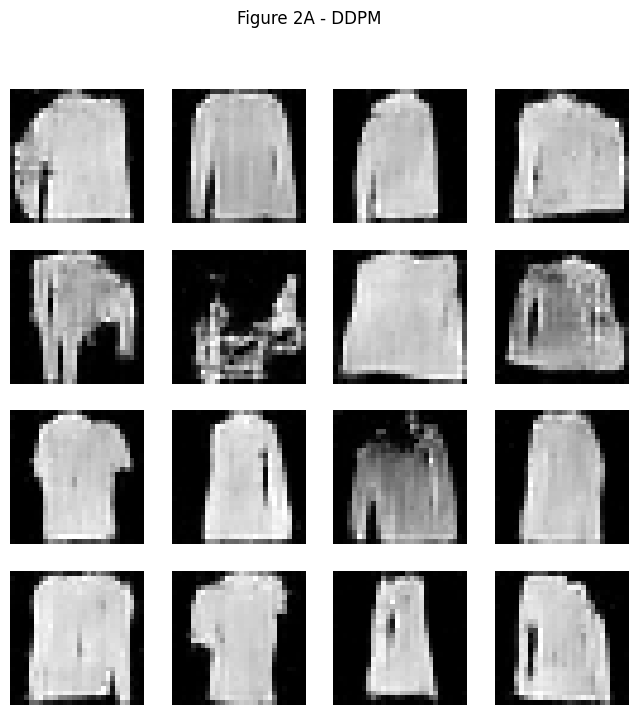

In [45]:
fig,axes = plt.subplots(
    4,
    4,
    figsize=(8,8)
)

for i in range(16):

    axes[i//4,i%4].imshow(
        ddpm_samples[i]
        .cpu()
        .reshape(28,28),
        cmap='gray'
    )

    axes[i//4,i%4].axis('off')

plt.suptitle("Figure 2A - DDPM")

plt.savefig(
    "Figure2A_DDPM.png",
    dpi=300
)

plt.show()

In [46]:
#Figure 3
img,_ = test_dataset[0]

img_input = img.unsqueeze(0).to(device)

In [47]:
#Transpose Projection
y = torch.zeros(10).to(device)

y[3] = 1

z_hat = torch.relu(
    W3.T @ y
)

h_hat = torch.relu(
    W2.T @ z_hat
)

transpose_img = torch.sigmoid(
    W1.T @ h_hat
)
#Latent Projection
with torch.no_grad():

    _,z = classifier(
        img_input
    )

latent_img = torch.sigmoid(

    W1.T @

    torch.relu(
        W2.T @ z.squeeze()
    )
)
#Random Latent
random_latent = torch.randn(
    64
).to(device)

sampling_img = torch.sigmoid(

    W1.T @

    torch.relu(
        W2.T @ random_latent
    )
)

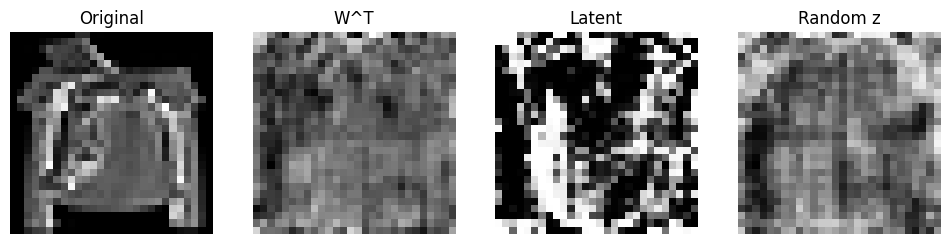

In [48]:
plt.figure(figsize=(12,3))

plt.subplot(1,4,1)

plt.imshow(
    img.squeeze(),
    cmap='gray'
)

plt.title("Original")

plt.axis('off')

plt.subplot(1,4,2)

plt.imshow(
    transpose_img.cpu().reshape(28,28),
    cmap='gray'
)

plt.title("W^T")

plt.axis('off')

plt.subplot(1,4,3)

plt.imshow(
    latent_img.cpu().reshape(28,28),
    cmap='gray'
)

plt.title("Latent")

plt.axis('off')

plt.subplot(1,4,4)

plt.imshow(
    sampling_img.cpu().reshape(28,28),
    cmap='gray'
)

plt.title("Random z")

plt.axis('off')

plt.savefig(
    "Figure3_MLP_Proof.png",
    dpi=300
)

plt.show()

In [49]:
# α
# 0
# 0.2
# 0.4
# 0.6
# 0.8
# 1
imgA,_ = test_dataset[0]

imgB,_ = test_dataset[100]
with torch.no_grad():

    _,zA = ae(
        imgA.unsqueeze(0).to(device)
    )

    _,zB = ae(
        imgB.unsqueeze(0).to(device)
    )
alphas = [
    0,
    0.2,
    0.4,
    0.6,
    0.8,
    1
]

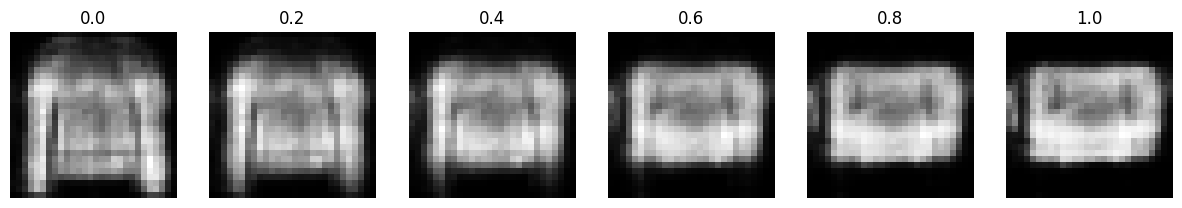

In [50]:
plt.figure(figsize=(15,3))

for i,a in enumerate(alphas):

    z = (
        (1-a)*zA +
        a*zB
    )

    img_interp = ae.decoder(z)

    plt.subplot(
        1,
        6,
        i+1
    )

    plt.imshow(
        img_interp
        .detach()
        .cpu()
        .reshape(28,28),
        cmap='gray'
    )

    plt.title(f"{a:.1f}")

    plt.axis('off')

plt.savefig(
    "Figure4_AE_Interpolation.png",
    dpi=300
)

plt.show()

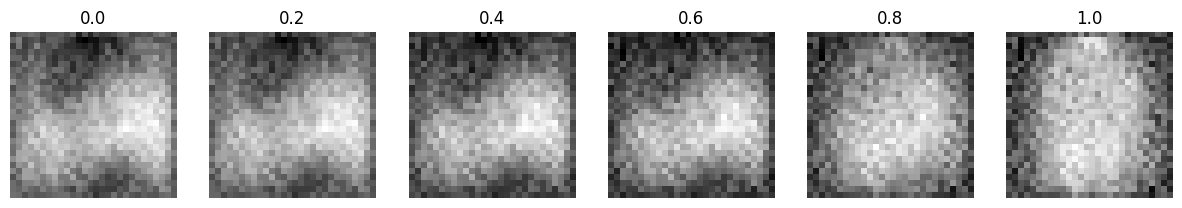

In [51]:
zA = torch.randn(
    1,
    100
).to(device)

zB = torch.randn(
    1,
    100
).to(device)
alphas = [0,0.2,0.4,0.6,0.8,1]

plt.figure(figsize=(15,3))

for i,a in enumerate(alphas):

    z = (1-a)*zA + a*zB

    img = G(z)

    plt.subplot(1,6,i+1)

    plt.imshow(
        img
        .detach()
        .cpu()
        .reshape(28,28),
        cmap='gray'
    )

    plt.title(f"{a:.1f}")

    plt.axis('off')

plt.savefig(
    "Figure4_GAN_Interpolation.png",
    dpi=300
)

plt.show()

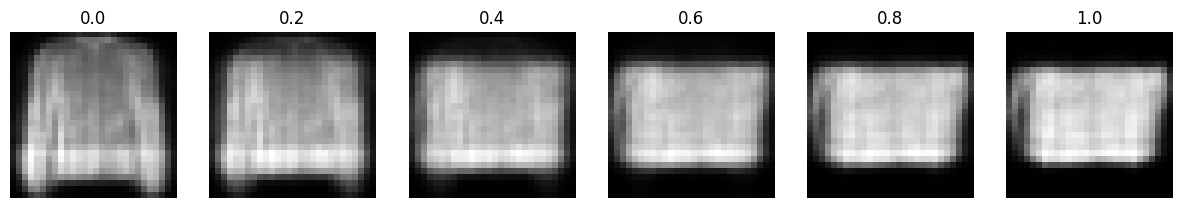

In [52]:
imgA,_ = test_dataset[0]
imgB,_ = test_dataset[100]

with torch.no_grad():

    muA,logvarA = vae.encode(
        imgA.view(1,-1).to(device)
    )

    muB,logvarB = vae.encode(
        imgB.view(1,-1).to(device)
    )
alphas = [0,0.2,0.4,0.6,0.8,1]

plt.figure(figsize=(15,3))

for i,a in enumerate(alphas):

    z = (1-a)*muA + a*muB

    img_interp = vae.decode(z)

    plt.subplot(1,6,i+1)

    plt.imshow(
        img_interp
        .detach()
        .cpu()
        .reshape(28,28),
        cmap='gray'
    )

    plt.title(f"{a:.1f}")

    plt.axis('off')

plt.savefig(
    "Figure4_VAE_Interpolation.png",
    dpi=300
)

plt.show()

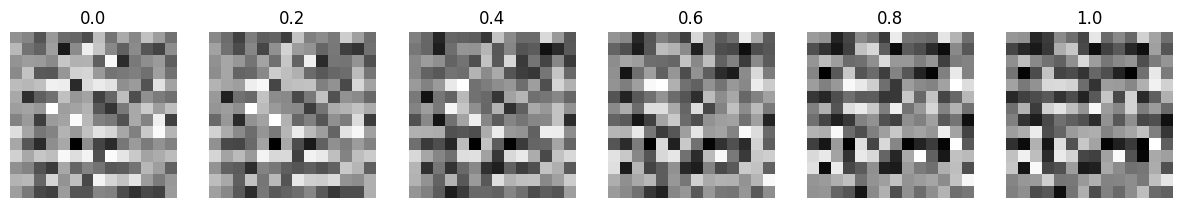

In [53]:

zA = torch.randn(
    1,
    100,
    1,
    1
).to(device)

zB = torch.randn(
    1,
    100,
    1,
    1
).to(device)

alphas = [0,0.2,0.4,0.6,0.8,1]

plt.figure(figsize=(15,3))

for i,a in enumerate(alphas):

    z = (1-a)*zA + a*zB

    img = G_dc(z)

    plt.subplot(1,6,i+1)

    plt.imshow(
        img
        .detach()
        .cpu()
        .squeeze(),
        cmap='gray'
    )

    plt.title(f"{a:.1f}")

    plt.axis('off')

plt.savefig(
    "Figure4_DCGAN_Interpolation.png",
    dpi=300
)

plt.show()

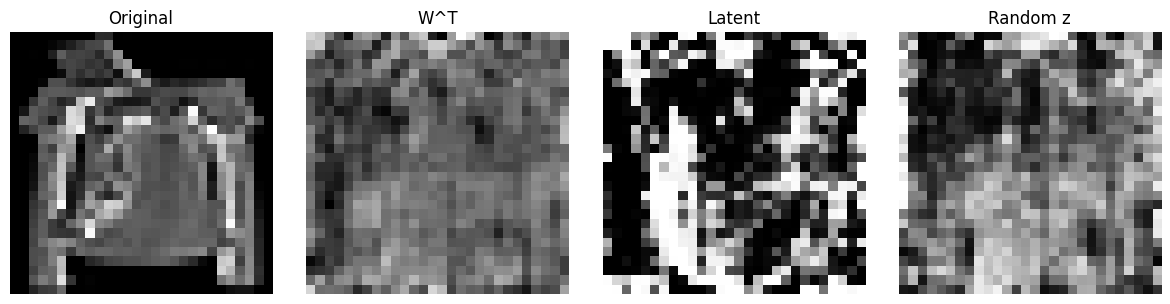

In [54]:
# Original
# Transpose Projection
# Frozen Decoder
# Random zMLP Sampling
# Bukti MLP
img,_ = test_dataset[0]

img_input = img.unsqueeze(0).to(device)

# Original
original = img.squeeze()

# Latent dari classifier
classifier.eval()

with torch.no_grad():

    _,z = classifier(img_input)

# Weight Transpose Projection
y = torch.zeros(10).to(device)
y[3] = 1

z_hat = torch.relu(W3.T @ y)

h_hat = torch.relu(W2.T @ z_hat)

transpose_img = torch.sigmoid(
    W1.T @ h_hat
)

# Latent Projection
latent_img = torch.sigmoid(
    W1.T @
    torch.relu(
        W2.T @ z.squeeze()
    )
)

# Random Sampling
random_z = torch.randn(64).to(device)

sampling_img = torch.sigmoid(
    W1.T @
    torch.relu(
        W2.T @ random_z
    )
)

plt.figure(figsize=(12,3))

plt.subplot(1,4,1)
plt.imshow(original, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,4,2)
plt.imshow(
    transpose_img.detach().cpu().reshape(28,28),
    cmap='gray'
)
plt.title("W^T")
plt.axis('off')

plt.subplot(1,4,3)
plt.imshow(
    latent_img.detach().cpu().reshape(28,28),
    cmap='gray'
)
plt.title("Latent")
plt.axis('off')

plt.subplot(1,4,4)
plt.imshow(
    sampling_img.detach().cpu().reshape(28,28),
    cmap='gray'
)
plt.title("Random z")
plt.axis('off')

plt.tight_layout()

plt.savefig(
    "Figure3_MLP_Proof.png",
    dpi=300
)

plt.show()

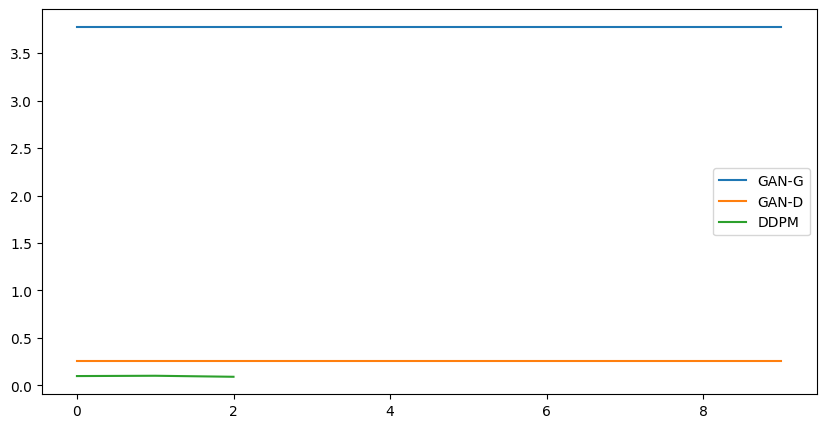

In [56]:

gan_g_losses = []
gan_d_losses = []

for epoch in range(10):

    ...

    gan_g_losses.append(
        g_loss.item()
    )

    gan_d_losses.append(
        d_loss.item()
    )
plt.figure(figsize=(10,5))

if len(gan_g_losses)>0:
    plt.plot(
        gan_g_losses,
        label='GAN-G'
    )

if len(gan_d_losses)>0:
    plt.plot(
        gan_d_losses,
        label='GAN-D'
    )

if len(ddpm_losses)>0:
    plt.plot(
        ddpm_losses,
        label='DDPM'
    )

plt.legend()
plt.show()

In [57]:
ae_result = evaluate_model(
    ae,
    test_loader
)

print(
    "AE Evaluation:",
    ae_result
)
sparse_result = evaluate_model(
    sparse_ae,
    test_loader
)

print(
    "Sparse AE Evaluation:",
    sparse_result
)
def evaluate_vae(model, loader):

    model.eval()

    mse_list = []
    psnr_list = []
    ssim_list = []

    with torch.no_grad():

        for images,_ in loader:

            images = images.to(device)

            recon,mu,logvar = model(images)

            recon = recon.view(-1,28,28)

            images = images.squeeze(1)

            for i in range(len(images)):

                img = images[i].cpu().numpy()

                rec = recon[i].cpu().numpy()

                mse = np.mean(
                    (img-rec)**2
                )

                p = peak_signal_noise_ratio(
                    img,
                    rec,
                    data_range=1
                )

                s = structural_similarity(
                    img,
                    rec,
                    data_range=1
                )

                mse_list.append(mse)
                psnr_list.append(p)
                ssim_list.append(s)

    return {

        "MSE": float(np.mean(mse_list)),

        "PSNR": float(np.mean(psnr_list)),

        "SSIM": float(np.mean(ssim_list))
    }


vae_result = evaluate_vae(
    vae,
    test_loader
)

print(
    "VAE Evaluation:",
    vae_result
)

AE Evaluation: {'MSE': np.float32(0.009214256), 'PSNR': np.float64(21.3000473567572), 'SSIM': np.float64(0.7716984550138039)}
Sparse AE Evaluation: {'MSE': np.float32(0.008950473), 'PSNR': np.float64(21.441081613300675), 'SSIM': np.float64(0.7723151321050857)}
VAE Evaluation: {'MSE': 0.017133524641394615, 'PSNR': 18.255226395466014, 'SSIM': 0.6546828057743943}


In [59]:
classifier.eval()

correct = 0
total = 0

with torch.no_grad():

    for images,labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs,_ = classifier(images)

        pred = outputs.argmax(1)

        correct += (
            pred==labels
        ).sum().item()

        total += labels.size(0)

mlp_accuracy = (
    100 * correct / total
)

print(
    f"MLP Accuracy = {mlp_accuracy:.2f}%"
)

MLP Accuracy = 88.87%


In [60]:
print("\n========== FINAL RESULTS ==========\n")

print(
    f"MLP Accuracy : {mlp_accuracy:.2f}%"
)

print("\nAE")
print(ae_result)

print("\nSparse AE")
print(sparse_result)

print("\nVAE")
print(vae_result)

print("\nGAN")
print("MSE   : N/A")
print("PSNR  : N/A")
print("SSIM  : N/A")

print("\nDCGAN")
print("MSE   : N/A")
print("PSNR  : N/A")
print("SSIM  : N/A")

print("\nDDPM")
print("MSE   : N/A")
print("PSNR  : N/A")
print("SSIM  : N/A")


========== FINAL RESULTS ==========

MLP Accuracy : 88.87%

AE
{'MSE': np.float32(0.009214256), 'PSNR': np.float64(21.3000473567572), 'SSIM': np.float64(0.7716984550138039)}

Sparse AE
{'MSE': np.float32(0.008950473), 'PSNR': np.float64(21.441081613300675), 'SSIM': np.float64(0.7723151321050857)}

VAE
{'MSE': 0.017131157219409943, 'PSNR': 18.256591398529302, 'SSIM': 0.654367786758464}

GAN
MSE   : N/A
PSNR  : N/A
SSIM  : N/A

DCGAN
MSE   : N/A
PSNR  : N/A
SSIM  : N/A

DDPM
MSE   : N/A
PSNR  : N/A
SSIM  : N/A
